# 1.安装依赖与初始化大模型

In [11]:
# 安装完整依赖包
!pip install -q langchain-openai langgraph chromadb tabulate pydantic matplotlib

import os
import re
import time
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import TypedDict, List, Dict, Any
from IPython.display import display, Markdown
from kaggle_secrets import UserSecretsClient
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END

# ==============================================================================
# V1.5 异构多模型路由器 (Role-Based Resilient LLM Router)
# ==============================================================================
class HeterogeneousLLMRouter:
    def __init__(self):
        self.user_secrets = UserSecretsClient()
        self.providers = []
        self.role_stats: Dict[str, Dict[str, int]] = {}
        # 跨组降级链：专属角色组全限流时，自动向次优组平滑降级
        self.fallback_order = {
            "fast":     ["fast", "coder", "writer", "reasoner"],
            "coder":    ["coder", "reasoner", "debugger", "fast"],
            "reasoner": ["reasoner", "debugger", "coder", "writer"],
            "debugger": ["debugger", "reasoner", "coder", "writer"],
            "writer":   ["writer", "reasoner", "coder", "fast"],
            "judge":    ["judge", "debugger", "reasoner", "coder"],
            "default":  ["coder", "reasoner", "writer", "fast"]
        }
        self._init_providers()
        
    def _get_secret_safe(self, key_name: str) -> str:
        try:
            val = self.user_secrets.get_secret(key_name)
            return val.strip() if val else ""
        except Exception:
            return ""

    def _init_providers(self):
        # 注意：列表顺序即同角色组内的【优先命中顺序】！
        # 核心设计：GLM4-Flash 专职 fast/writer，严禁写复杂 SQL；
        # Qwen27B 主攻 coder；Qwen35B 主攻 debugger/reasoner；
        # Gemini 3.5 Flash 主攻异源 judge！
        candidate_configs = [
            # 1. 阿里魔搭 ModelScope (主力推理与代码底座)
            {
                "name": "ModelScope-Qwen3.5-35B",
                "secret_key": "MODELSCOPE_API_KEY",
                "model": "Qwen/Qwen3.5-35B-A3B",
                "base_url": "https://api-inference.modelscope.cn/v1/",
                "roles": ["debugger", "reasoner", "coder", "judge"],
                "timeout": 40,
                "min_interval": 2.0
            },
            {
                "name": "ModelScope-Qwen3.8-27B",
                "secret_key": "MODELSCOPE_API_KEY",
                "model": "Qwen/Qwen3.8-27B",
                "base_url": "https://api-inference.modelscope.cn/v1/",
                "roles": ["coder", "writer", "reasoner", "debugger"],
                "timeout": 25,
                "min_interval": 2.0
            },
            # 2. Google Gemini (异源裁判与高速备选)
            {
                "name": "Google-Gemini-3.5-Flash",
                "secret_key": "GEMINI API KEY",
                "model": "gemini-3.5-flash-lite",
                "base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "roles": ["judge", "coder", "fast"],
                "timeout": 20,
                "min_interval": 2.0
            },
            {
                "name": "Google-Gemini-4-hydrogen",
                "secret_key": "GEMINI API KEY",
                "model": "gemini-4-hydrogen",
                "base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "roles": ["debugger", "judge"],
                "timeout": 20,
                "min_interval": 2.0
            },
            {
                "name": "Google-Gemini-3.8-Flash",
                "secret_key": "GEMINI API KEY",
                "model": "gemini-3.8-flash",
                "base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "roles": ["coder", "judge"],
                "timeout": 20,
                "min_interval": 2.0
            },
            # 3. 智谱 BigModel (高频轻量路由与中文写作备选，严禁参与复杂 SQL)
            {
                "name": "Zhipu-GLM4-Flash-250414",
                "secret_key": "ZHIPU_API_KEY",
                "model": "glm-4-flash-250414",
                "base_url": "https://open.bigmodel.cn/api/paas/v4/",
                "roles": ["fast", "writer"],
                "timeout": 20,
                "min_interval": 3.0
            },
            {
                "name": "Zhipu-GLM4-Flash",
                "secret_key": "ZHIPU_API_KEY",
                "model": "glm-4-flash",
                "base_url": "https://open.bigmodel.cn/api/paas/v4/",
                "roles": ["fast", "writer"],
                "timeout": 20,
                "min_interval": 3.0
            }
        ]
        
        for cfg in candidate_configs:
            api_key = self._get_secret_safe(cfg["secret_key"])
            if api_key:
                client = ChatOpenAI(
                    model=cfg["model"],
                    api_key=api_key,
                    base_url=cfg["base_url"],
                    temperature=0.0,
                    max_retries=0,
                    timeout=cfg["timeout"]
                )
                self.providers.append({
                    "name": cfg["name"],
                    "client": client,
                    "roles": cfg["roles"],
                    "min_interval": cfg["min_interval"],
                    "cooldown_until": 0.0,
                    "last_call_time": 0.0,
                    "success_cnt": 0,
                    "fail_cnt": 0
                })
                
        assert len(self.providers) > 0, "未检测到任何 API Key，请检查 Kaggle Secrets！"
        print(f"✅ 已加载 {len(self.providers)} 条异构模型通道（已按角色能力分层）。")

    def _clean_think(self, text: str) -> str:
        """剥离推理模型可能附带的 <think>...</think> 思考块，防止 SQL/JSON 解析失败"""
        if "<think>" in text and "</think>" in text:
            return re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()
        return text

    def _apply_cooldown(self, p: Dict, err_str: str) -> str:
        e = err_str.lower()
        if any(k in e for k in ["404", "not found", "does not exist", "400"]):
            cd, tag = 600.0, "模型不可用(屏蔽600s)"
        elif any(k in e for k in ["429", "rate", "limit", "quota", "1302"]):
            cd, tag = 60.0, "限流429(冷却60s)"
        elif any(k in e for k in ["timed out", "timeout"]):
            cd, tag = 120.0, "请求超时(熔断120s)"
        elif any(k in e for k in ["503", "high demand", "overloaded"]):
            cd, tag = 45.0, "服务拥堵503(冷却45s)"
        else:
            cd, tag = 30.0, "连接异常(冷却30s)"
        p["cooldown_until"] = time.time() + cd
        return tag

    def invoke(self, input_data: Any, role: str = "default", temperature: float = 0.0, verbose: bool = False) -> AIMessage:
        tier_chain = self.fallback_order.get(role, ["coder", "reasoner", "fast"])
        candidates, seen = [], set()
        for tier in tier_chain:
            for p in self.providers:
                if tier in p["roles"] and p["name"] not in seen:
                    candidates.append((tier, p))
                    seen.add(p["name"])

        last_err = None
        for round_idx in range(2):  # 最多两轮（若第一轮全在冷却则等待最快恢复者）
            now = time.time()
            available = [(t, p) for t, p in candidates if now >= p["cooldown_until"]]
            if not available:
                earliest_t, earliest_p = min(candidates, key=lambda x: x[1]["cooldown_until"])
                wait_sec = max(1.0, earliest_p["cooldown_until"] - now)
                print(f"  ⏳ 角色 [{role}] 候选通道均在冷却，等待 {wait_sec:.1f}s 后由 [{earliest_p['name']}] 恢复...")
                time.sleep(wait_sec)
                available = [(earliest_t, earliest_p)]

            for matched_tier, p in available:
                # 单通道安全间隔保护
                elapsed = time.time() - p["last_call_time"]
                if elapsed < p["min_interval"]:
                    time.sleep(p["min_interval"] - elapsed)
                try:
                    p["last_call_time"] = time.time()
                    # 修复 Bug：让 temperature 参数真正生效！
                    client_to_use = p["client"].bind(temperature=temperature) if temperature > 0.0 else p["client"]
                    res = client_to_use.invoke(input_data)
                    clean_text = self._clean_think(res.content)
                    
                    p["success_cnt"] += 1
                    self.role_stats.setdefault(role, {})
                    self.role_stats[role][p["name"]] = self.role_stats[role].get(p["name"], 0) + 1
                    if verbose:
                        deg = "" if matched_tier == role else f" [降级自{matched_tier}]"
                        print(f"  🔀 [Router | Role={role:<8}] -> [{p['name']}]{deg}")
                    return AIMessage(content=clean_text)
                except Exception as e:
                    last_err = e
                    p["fail_cnt"] += 1
                    tag = self._apply_cooldown(p, str(e))
                    print(f"  ⚠️ 通道 [{p['name']}] {tag} -> 秒切下一通道")
                    time.sleep(0.8)

        raise RuntimeError(f"❌ 角色 [{role}] 所有异构通道均调用失败，最后报错: {last_err}")

    def for_role(self, role: str, temperature: float = 0.0, verbose: bool = True):
        """生成角色专属代理对象，完美兼容 .invoke(messages) 标准接口"""
        router_ref = self
        class _RoleProxy:
            def invoke(self, input_data):
                return router_ref.invoke(input_data, role=role, temperature=temperature, verbose=verbose)
        return _RoleProxy()

    def diagnose_providers(self):
        print("正在对全部可用模型通道进行连通性与耗时体检...\n")
        for p in self.providers:
            t0 = time.time()
            try:
                p["last_call_time"] = time.time()
                res = p["client"].invoke("只回复两个字：正常")
                cost = time.time() - t0
                print(f"  [{p['name']:<26}] 连通! {cost:5.2f}s | 角色:{','.join(p['roles']):<30} | 状态: {res.content.strip()[:12]}")
            except Exception as e:
                cost = time.time() - t0
                tag = self._apply_cooldown(p, str(e))
                print(f"  [{p['name']:<26}] 失败! {cost:5.2f}s | {tag} | {str(e)[:45]}")
            time.sleep(1.5)

    def print_stats(self):
        stats = [{
            "通道名称": p["name"], "负责角色": ",".join(p["roles"]),
            "成功次数": p["success_cnt"], "异常切换": p["fail_cnt"],
            "状态": "正常" if time.time() >= p["cooldown_until"] else "冷却中"
        } for p in self.providers]
        display(Markdown("#### 📡 通道健康度统计"))
        display(Markdown(pd.DataFrame(stats).to_markdown(index=False)))
        if self.role_stats:
            role_rows = [{"Agent角色": r, "模型路由分布": " | ".join([f"{k}: {v}次" for k, v in m.items()])} for r, m in self.role_stats.items()]
            display(Markdown("#### 🔀 异构多模型 FinOps 角色分流统计"))
            display(Markdown(pd.DataFrame(role_rows).to_markdown(index=False)))

# 实例化总路由器 + 6大子 Agent 专属模型代理
llm = HeterogeneousLLMRouter()
llm.diagnose_providers()

llm_gateway  = llm.for_role("fast",     temperature=0.0, verbose=False)
llm_planner  = llm.for_role("reasoner", temperature=0.1, verbose=True)
llm_sql_gen  = llm.for_role("coder",    temperature=0.0, verbose=False)
llm_debugger = llm.for_role("debugger", temperature=0.0, verbose=True)
llm_reporter = llm.for_role("writer",   temperature=0.25, verbose=True)
llm_judge    = llm.for_role("judge",    temperature=0.0, verbose=True)

✅ 已加载 7 条异构模型通道（已按角色能力分层）。
正在对全部可用模型通道进行连通性与耗时体检...

  [ModelScope-Qwen3.5-35B    ] 连通!  4.20s | 角色:debugger,reasoner,coder,judge  | 状态: 正常
  [ModelScope-Qwen3.8-27B    ] 连通!  5.83s | 角色:coder,writer,reasoner,debugger | 状态: 正常
  [Google-Gemini-3.5-Flash   ] 连通!  7.08s | 角色:judge,coder,fast               | 状态: 正常
  [Google-Gemini-4-hydrogen  ] 失败!  0.73s | 服务拥堵503(冷却45s) | Error code: 503 - [{'error': {'code': 503, 'm
  [Google-Gemini-3.8-Flash   ] 失败! 20.02s | 请求超时(熔断120s) | Request timed out.
  [Zhipu-GLM4-Flash-250414   ] 连通!  1.09s | 角色:fast,writer                    | 状态: 正常
  [Zhipu-GLM4-Flash          ] 连通!  2.74s | 角色:fast,writer                    | 状态: 正常


# 2.构建全量本地数仓

In [12]:
# 1. 自动检索 Kaggle 挂载的 Olist 数据集路径
data_dir = ""
for root, dirs, files in os.walk("/kaggle/input"):
    if "olist_orders_dataset.csv" in files:
        data_dir = root
        break

assert data_dir != "", "未找到数据集，请在右侧 Input 面板挂载 Brazilian E-Commerce Public Dataset！"

# 2. 创建 SQLite 数据库并导入全部 8 张核心表
db_path = "/kaggle/working/olist_enterprise.db"
conn = sqlite3.connect(db_path)

tables_map = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "sellers": "olist_sellers_dataset.csv"
}

print("正在构建企业级模拟数仓...")
for table_name, file_name in tables_map.items():
    df = pd.read_csv(os.path.join(data_dir, file_name))
    df.to_sql(table_name, conn, if_exists="replace", index=False)
    print(f"  ├─ 表 [{table_name:<20}] 导入成功 | 行数: {len(df):<8} | 核心字段: {list(df.columns[:4])}...")
print("数仓构建完毕！")

正在构建企业级模拟数仓...
  ├─ 表 [orders              ] 导入成功 | 行数: 99441    | 核心字段: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp']...
  ├─ 表 [order_items         ] 导入成功 | 行数: 112650   | 核心字段: ['order_id', 'order_item_id', 'product_id', 'seller_id']...
  ├─ 表 [order_payments      ] 导入成功 | 行数: 103886   | 核心字段: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments']...
  ├─ 表 [customers           ] 导入成功 | 行数: 99441    | 核心字段: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city']...
  ├─ 表 [products            ] 导入成功 | 行数: 32951    | 核心字段: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght']...
  ├─ 表 [category_translation] 导入成功 | 行数: 71       | 核心字段: ['product_category_name', 'product_category_name_english']...
  ├─ 表 [order_reviews       ] 导入成功 | 行数: 99224    | 核心字段: ['review_id', 'order_id', 'review_score', 'review_comment_title']...
  ├─ 表 [sellers             ] 导入成功 | 行数: 3095     | 核

# 3.构建BI知识库

除了把业务知识注入外，还加上了检索功能，为什么需要进行检索，而不直接每次都查全部知识库信息就行？
1. 真实业务场景往往数据表很多，如果每次都查询全部信息，会有：
   - 大模型响应速度变慢
   - 超出大模型上下文窗口上限
   - 消耗更多的token，成本上涨
2. 如果某些表信息接近，可能稀释大模型注意力，选错相近字段从而得到错误的结果

In [13]:
import chromadb

chroma_client = chromadb.Client()
try:
    chroma_client.delete_collection("enterprise_bi_kb")
except:
    pass
collection = chroma_client.create_collection(name="enterprise_bi_kb")

# 1. 数仓表结构与主外键关联规范 
schema_docs = [
    "【表结构：orders (订单主表)】主键: order_id | 关联键: customer_id | 字段: order_status(状态: delivered已送达, canceled已取消, shipped已发货等), order_purchase_timestamp(下单时间), order_approved_at(支付审批时间), order_delivered_customer_date(实际送达客户时间), order_estimated_delivery_date(预计送达时间)。",
    "【表结构：order_items (订单商品明细表)】联合主键: (order_id, order_item_id) | 字段: product_id(商品ID), seller_id(卖家ID), price(单件商品售价，不含运费), freight_value(单件商品运费)。注意：一笔订单买N件商品就会有N行记录！",
    "【表结构：order_payments (订单支付明细表)】联合主键: (order_id, payment_sequential) | 字段: payment_type(支付方式: credit_card, boleto, voucher, debit_card), payment_installments(分期数), payment_value(该笔支付金额)。注意：一笔订单可能有多次支付记录（多行）！",
    "【表结构：customers (客户表)】主键: customer_id(单笔订单绑定的临时客户ID) | 核心字段: customer_unique_id(客户真实唯一标识ID，同一个人在不同订单中 customer_unique_id 相同，但 customer_id 不同！), customer_city, customer_state(州缩写，如 'SP', 'RJ', 'MG')。",
    "【表结构：products & category_translation (商品与英文品类映射表)】products表主键: product_id，含葡萄牙语品类名 product_category_name；必须通过 LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name 获取英文品类名 product_category_name_english。",
    "【表结构：order_reviews (订单评价表)】字段: review_id, order_id, review_score(评分1到5分)。注意：同一个 order_id 可能存在多条评价记录。"
]

# 2. 定义指标口径与注意事项
metric_docs = [
    "【口径1：有效订单与有效GMV (Net Valid GMV)】除非特别说明，所有‘有效订单’、‘有效GMV’、‘销售额’均要求过滤 orders.order_status = 'delivered'。有效GMV = SUM(order_items.price)，即仅统计商品售价总和，不含运费(freight_value)。",
    "【口径2：独立买家数 (UV)】统计买家人数、独立客户数或UV时，必须关联 customers 表并使用 COUNT(DISTINCT customers.customer_unique_id)，严禁使用 COUNT(DISTINCT customer_id)！",
    "【口径3：客单价 (AOV) 与 件单价 (ASP) 区分】有效客单价 (AOV) = SUM(order_items.price) / COUNT(DISTINCT orders.order_id)，分母必须是去重后的有效订单数；有效件单价 (ASP) = SUM(order_items.price) / COUNT(order_items.order_item_id)，分母是商品件数（明细行数）。",
    "【口径4：订单连带率 (UPT / Attach Rate)】指平均每笔有效订单包含的商品件数，计算公式为：COUNT(order_items.order_item_id) * 1.0 / COUNT(DISTINCT orders.order_id)（需限定 order_status = 'delivered'）。",
    "【口径5：订单取消率 (Order Cancellation Rate)】在指定下单时间范围内所有订单中，状态为 canceled 的订单占比，公式：SUM(CASE WHEN order_status = 'canceled' THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(DISTINCT order_id)。注意：算取消率时 WHERE 条件不能过滤 order_status = 'delivered'！",
    "【口径6：平均履约时长 (Avg Delivery Days) 与 履约延迟率 (Delay Rate)】均限定在 order_status = 'delivered' 且 order_delivered_customer_date IS NOT NULL 的订单中。平均履约时长(天) = AVG(julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp))；履约延迟率(%) = AVG(CASE WHEN julianday(order_delivered_customer_date) > julianday(order_estimated_delivery_date) THEN 1.0 ELSE 0.0 END) * 100.0。",
    "【口径7：有效订单差评率 (Bad Review Rate)】在已送达(delivered)且关联到评价表(order_reviews)的订单中，评分 <= 2 分的去重订单数除以总参评去重有效订单数，公式：COUNT(DISTINCT CASE WHEN r.review_score <= 2 THEN o.order_id END) * 100.0 / COUNT(DISTINCT o.order_id)。必须用 INNER JOIN order_reviews r ON o.order_id = r.order_id。",
    "【口径8：防扇出膨胀规范（一对多关联防笛卡尔积 Fan-out Trap）】由于 order_items（一单多品）和 order_payments（一单多次支付）或 order_reviews 同属订单的下游一对多明细表，当需要按支付方式（如 credit_card）筛选并统计商品有效GMV（SUM(oi.price)）时，严禁直接将 order_items 与 order_payments 直接 JOIN 后求和！必须使用子查询过滤：WHERE o.order_id IN (SELECT DISTINCT order_id FROM order_payments WHERE payment_type = 'credit_card')。",
    "【口径9：周期用户复购率 (Repeat Purchase Rate)】在指定统计周期内产生过有效订单(delivered)的独立买家中，有效订单数 >= 2 笔的独立买家占比(%)。必须先用 CTE 按 customer_unique_id 聚合计算 order_cnt = COUNT(DISTINCT o.order_id)，再用 SUM(CASE WHEN order_cnt >= 2 THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(customer_unique_id)。",
    "【口径10：新老客界定口径 (New vs Returning Customer)】以真实用户 customer_unique_id 在全量历史有效订单(delivered)中的首次下单时间 min_purchase_time = MIN(order_purchase_timestamp) 为准。若某用户在全量历史中的首次有效下单时间早于目标统计周期的起始时间（例如分析2018-08时，其首次有效下单时间 < '2018-08-01'），则该用户在目标周期内属于【老客】；否则属于【新客】。"
]

# 3. 复杂SQL参考样本
golden_sql_docs = [
    """【参考范式1：防扇出膨胀（统计特定支付方式下的有效GMV）】
    SELECT ROUND(SUM(oi.price), 2) AS val
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
      AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
      AND o.order_id IN (SELECT DISTINCT order_id FROM order_payments WHERE payment_type = 'credit_card');""",

    """【参考范式2：使用 CTE 计算周期用户复购率(%)】
    WITH user_orders AS (
        SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS ord_cnt
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
          AND strftime('%Y', o.order_purchase_timestamp) = '2018'
        GROUP BY c.customer_unique_id
    )
    SELECT ROUND(SUM(CASE WHEN ord_cnt >= 2 THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(customer_unique_id), 2) AS val
    FROM user_orders;""",

    """【参考范式3：使用 CTE 界定历史老客并统计其在目标月份贡献的有效GMV】
    WITH user_first_order AS (
        SELECT c.customer_unique_id, MIN(o.order_purchase_timestamp) AS first_order_time
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    )
    SELECT ROUND(SUM(oi.price), 2) AS val
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN user_first_order ufo ON c.customer_unique_id = ufo.customer_unique_id
    WHERE o.order_status = 'delivered'
      AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
      AND ufo.first_order_time < '2018-08-01';"""
]

all_kb_docs = schema_docs + metric_docs + golden_sql_docs
collection.add(
    documents=all_kb_docs,
    ids=[f"kb_{i}" for i in range(len(all_kb_docs))]
)

# 语义检索
# 常驻全量紧凑 Schema（与动态口径检索隔离，永不漏掉 category_translation！）
GLOBAL_COMPACT_SCHEMA = "\n".join(schema_docs) + "\n【关联规定】：查英文商品品类必须用 LEFT JOIN products p ON oi.product_id = p.product_id LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name，并用 COALESCE(t.product_category_name_english, 'unknown') 兜底，严禁 INNER JOIN 导致大盘分母偏小！"

# 纯规则与SQL范式池（不与表结构互相挤占 Top-K）
rules_and_sql_pool = metric_docs + golden_sql_docs

def retrieve_bi_context(query: str, top_k: int = 6) -> str:
    """
    V1.5 混合检索 (Hybrid RAG)：中文字符 2-gram 词法匹配(0.7) + ChromaDB 向量(0.3) RRF 融合重排
    """
    # 动态同步最新入库（含 Debugger 自动沉淀的经验）
    all_now = collection.get()["documents"]
    dynamic_pool = [d for d in all_now if not d.startswith("【表结构")]
    
    q_clean = re.sub(r"[\s，。？！（）()：:、]", "", query.lower())
    q_ngrams = set(q_clean[i:i+2] for i in range(max(1, len(q_clean)-1)))
    
    lex_scored = []
    for doc in dynamic_pool:
        d_clean = re.sub(r"[\s，。？！（）()：:、]", "", doc.lower())
        d_ngrams = set(d_clean[i:i+2] for i in range(max(1, len(d_clean)-1)))
        lex_scored.append((len(q_ngrams & d_ngrams) / (len(q_ngrams) + 1e-5), doc))
    lex_scored.sort(key=lambda x: x[0], reverse=True)
    lex_rank = {doc: i + 1 for i, (_, doc) in enumerate(lex_scored)}
    
    vec_docs = collection.query(query_texts=[query], n_results=len(all_now))["documents"][0]
    vec_rank = {doc: i + 1 for i, doc in enumerate(vec_docs)}
    
    fused = sorted(
        [(0.7 / (10 + lex_rank.get(d, 99)) + 0.3 / (10 + vec_rank.get(d, 99)), d) for d in dynamic_pool],
        key=lambda x: x[0], reverse=True
    )
    top_rules = "\n\n".join([d for _, d in fused[:top_k]])
    return f"{GLOBAL_COMPACT_SCHEMA}\n\n【混合检索命中的核心口径与参考范式】：\n{top_rules}"

print(f"✅ V1.5 混合语义知识库就绪（Schema常驻 + {len(rules_and_sql_pool)} 条口径/范式混合检索）！")

✅ V1.5 混合语义知识库就绪（Schema常驻 + 13 条口径/范式混合检索）！


# 4.Text-to-SQL 自纠错 Agent

In [14]:
# ==============================================================================
# V1.5 Cell 4：SQL 安全护栏 + Agent A (Coder) + 独立异构 Debugger (Qwen35B) 自动排障重跑
# ==============================================================================
AUTO_LEARNED_LESSONS = []
BT3 = "`" * 3  # 构造三反引号，避免字符串嵌套干扰 Markdown 格式

def _assert_read_only_sql(sql: str):
    """只读静态安全护栏：阻断一切写操作与高危 DDL"""
    forbidden = ["DROP ", "DELETE ", "UPDATE ", "INSERT ", "ALTER ", "TRUNCATE ", "ATTACH "]
    if any(k in sql.upper() for k in forbidden):
        raise PermissionError(f"🚨 [SQL Security Guard] 拦截到高危写操作 SQL: {sql[:80]}")

# --- 4 个只读数据库主动探查工具 (专供独立 Debugger Agent 取证使用) ---
def _tool_list_all_tables() -> str:
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist()
    return "\n".join([f"- 表 `{t}`: {', '.join(pd.read_sql(f'PRAGMA table_info({t})', conn)['name'].tolist())}" for t in tables])

def _tool_search_columns(keyword: str) -> str:
    kw = keyword.lower().strip()
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist()
    hits = [f"`{t}.{c}`" for t in tables for c in pd.read_sql(f"PRAGMA table_info({t})", conn)["name"].tolist() if kw in c.lower() or kw in t.lower()]
    return ", ".join(hits) if hits else f"未找到含 '{keyword}' 的字段"

def _tool_peek_values(table_name: str, col_name: str) -> str:
    if not (re.match(r"^\w+$", table_name) and re.match(r"^\w+$", col_name)):
        return "非法表名或字段名"
    try:
        vals = pd.read_sql(f"SELECT DISTINCT {col_name} FROM {table_name} WHERE {col_name} IS NOT NULL LIMIT 10", conn)[col_name].tolist()
        return f"`{table_name}.{col_name}` 枚举样本: {vals}"
    except Exception as e:
        return f"抽样失败: {e}"

def _tool_scan_all_kb() -> str:
    return "\n".join([f"{i+1}. {d}" for i, d in enumerate(collection.get()["documents"])])

# --- Agent B：独立异构 SQL Debugger Agent（调用最强推理角色 llm_debugger） ---
def sql_debugger_agent(question: str, failed_sql: str, error_msg: str, auto_promote_to_rag: bool = True) -> Dict[str, Any]:
    print("  🕵️ [Agent B | 独立 Debugger 已接管现场] 调用异构推理模型排查根因...")
    
    # 步骤 1：自主规划数据库探查工具
    plan_prompt = f"""
            你是独立的资深数据库排障专家（SQL Debugger Agent）。上游 SQL Agent 执行失败，请你选择需要调用的探查工具获取一手证据。
            【用户问题】：{question}
            【失败 SQL】：{failed_sql}
            【报错信息】：{error_msg}
            
            可用工具：
            1. {{"tool": "list_all_tables"}}
            2. {{"tool": "search_columns", "keyword": "关键词"}}
            3. {{"tool": "peek_values", "table": "表名", "col": "字段名"}}
            4. {{"tool": "scan_all_kb"}}
            
            请只输出 JSON 数组（2~3个工具），如：[{{"tool": "list_all_tables"}}, {{"tool": "scan_all_kb"}}]
            """

    tool_resp = llm_debugger.invoke([HumanMessage(content=plan_prompt)]).content
    try:
        t_json = tool_resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in tool_resp else tool_resp.strip()
        tool_calls = json.loads(t_json)
    except Exception:
        tool_calls = [{"tool": "list_all_tables"}, {"tool": "scan_all_kb"}]

    evidences = []
    for tc in tool_calls:
        name = tc.get("tool")
        if name == "list_all_tables":
            evidences.append("【全库真实表结构】:\n" + _tool_list_all_tables())
        elif name == "search_columns":
            evidences.append(f"【字段搜索 '{tc.get('keyword','')}'】:\n" + _tool_search_columns(tc.get("keyword", "")))
        elif name == "peek_values":
            evidences.append("【枚举值抽样】:\n" + _tool_peek_values(tc.get("table", ""), tc.get("col", "")))
        elif name == "scan_all_kb":
            evidences.append("【全量业务口径字典】:\n" + _tool_scan_all_kb())

    # 步骤 2：依据一手证据修复 SQL 并提炼规则
    repair_prompt = f"""请结合以下【数据库一手探查证据】彻底修复失败 SQL，并提炼一条可复用避坑经验。
                    【用户问题】：{question}
                    【失败 SQL】：{failed_sql}
                    【报错信息】：{error_msg}
                    
                    {chr(10).join(evidences)}
                    
                    请严格按以下 3 个块输出：
                    <root_cause>一句话定位根因</root_cause>
                    {BT3}sql
                    -- 修复后的完整 SQLite 查询（若为单值统计，仅返回最终 1 列 AS val）
                    {BT3}
                    <lesson>客观、可复用的表结构或 SQLite 避坑经验</lesson>"""

    rep_resp = llm_debugger.invoke([HumanMessage(content=repair_prompt)]).content
    rc = re.search(r"<root_cause>(.*?)</root_cause>", rep_resp, re.S)
    ls = re.search(r"<lesson>(.*?)</lesson>", rep_resp, re.S)
    root_cause = rc.group(1).strip() if rc else "语法/口径修复"
    lesson = ls.group(1).strip() if ls else ""
    fixed_sql = rep_resp.split(f"{BT3}sql")[-1].split(BT3)[0].strip() if f"{BT3}sql" in rep_resp else ""

    print(f"  💡 [Debugger 诊断]: {root_cause}")
    try:
        _assert_read_only_sql(fixed_sql)
        df_fixed = pd.read_sql(fixed_sql, conn)
        if df_fixed.empty or df_fixed.iloc[0].isna().all():
            raise ValueError("修复后的 SQL 仍返回空表或全 NULL")
        print(f"  ✅ [Debugger 自动修复重跑成功！] 返回 {len(df_fixed)} 行")

        # 防投毒口径合规静态校验（防止漏写 delivered 或 unique_id 的伪成功 SQL 污染向量库）
        if lesson and auto_promote_to_rag:
            sql_up = fixed_sql.upper()
            safe_to_learn = True
            if ("有效" in question or "GMV" in question) and "DELIVERED" not in sql_up:
                safe_to_learn = False
            if ("UV" in question or "独立买家" in question) and "CUSTOMER_UNIQUE_ID" not in sql_up:
                safe_to_learn = False
            if safe_to_learn:
                lid = f"auto_lesson_{abs(hash(lesson)) % 100000}"
                collection.upsert(documents=[f"【Debugger自动沉淀经验】{lesson}\n参考SQL:\n{fixed_sql}"], ids=[lid])
                AUTO_LEARNED_LESSONS.append({"q": question, "root_cause": root_cause, "lesson": lesson})
                print(f"  🔄 [防投毒门控通过] 已自动沉淀经验至 ChromaDB ({lid})")
            else:
                print("  ⚠️ [防投毒门控拦截] 疑似缺失核心口径关键词，拒绝写入知识库")

        return {"status": "repaired", "sql": fixed_sql, "data": df_fixed.to_markdown(index=False), "df": df_fixed, "attempts": 2, "used_debugger": True, "error": None}
    except Exception as e:
        print(f"  ❌ [Debugger 重跑仍失败]: {e}")
        return {"status": "failed", "sql": fixed_sql, "data": "查询失败", "df": pd.DataFrame(), "attempts": 3, "used_debugger": True, "error": str(e)}

# --- 统一对外入口：Agent A (Coder) -> 失败自动移交 Agent B (Debugger) ---
def execute_sql_with_self_correction(task_description: str, max_retries: int = 2, verbose: bool = True) -> Dict[str, Any]:
    bi_context = retrieve_bi_context(task_description, top_k=6)
    system_prompt = f"""你是精通 SQLite 语法的资深电商 BI 架构师。请严格依据下方【数仓表结构与业务口径】编写 SQLite 查询语句。
【要求】：
1. 严格遵循业务口径（有效GMV过滤 delivered 且只算 price；UV/复购/老客用 customer_unique_id；跨支付表防扇出用 IN 子查询）。
2. 时间截断用 strftime('%Y-%m', col)，时间差用 julianday(col1) - julianday(col2)。
3. 只输出纯 SQL 代码，用 {BT3}sql 和 {BT3} 包裹，严禁输出多余文字。

{bi_context}"""
    messages = [SystemMessage(content=system_prompt), HumanMessage(content=f"查询任务：{task_description}")]
    
    sql, err_msg = "", ""
    # Agent A (专职 coder 模型) 先尝试快速执行（默认最多 2 次）
    for attempt in range(1, max_retries + 1):
        resp = llm_sql_gen.invoke(messages).content
        sql = resp.split(f"{BT3}sql")[-1].split(BT3)[0].strip() if f"{BT3}sql" in resp else resp.strip()
        try:
            _assert_read_only_sql(sql)
            df = pd.read_sql(sql, conn)
            if df.empty:
                raise ValueError("查询结果为空表（0行）")
            if df.iloc[0].isna().all():
                raise ValueError("查询结果首行全为 NULL")
            if verbose:
                print(f"  🟢 [Agent A | Coder] 第 {attempt} 次执行成功 (返回 {len(df)} 行)")
            return {"status": "success", "sql": sql, "data": df.to_markdown(index=False), "df": df, "attempts": attempt, "used_debugger": False, "error": None}
        except Exception as e:
            err_msg = str(e)
            if verbose:
                print(f"  🟡 [Agent A | Coder] 第 {attempt} 次异常 ({err_msg[:55]}...)")
            messages.append(AIMessage(content=resp))
            messages.append(HumanMessage(content=f"执行失败：【{err_msg}】。请修正后仅输出完整 {BT3}sql 代码块。"))

    # Agent A 连续失败 -> 正式移交给异构独立 Agent B (Debugger, Qwen3.5-35B) 主动探查数据库修复重跑！
    return sql_debugger_agent(question=task_description, failed_sql=sql, error_msg=err_msg, auto_promote_to_rag=True)

print("✅ V1.5 Actor-Debugger 异构 SQL 引擎与安全护栏已就绪！")

✅ V1.5 Actor-Debugger 异构 SQL 引擎与安全护栏已就绪！


# 5.基于 LangGraph 的多 Agent 异动归因

定义4个Agent角色：
1. Planner（规划Agent）：当用户问“为什么2018年8月销售额环比下降了？”时，Planner 不直接写SQL，而是结合业务知识拆解分析假设（假设1：某核心品类下跌；假设2：某重点城市物流延迟导致取消率上升）
2. SQL Executor（取数Agent）：并行或串行调用Text-to-SQL 模块，拉取不同维度的拆解数据
3. Analyst（分析Agent）：获取数据后，编写代码计算各维度的贡献度（Contribution Rate）或相关系数，并生成可视化图表保存
4. Reporter（报告Agent）：汇总上述图表和数据结论，输出结构化的归因分析报告

In [15]:
# ==============================================================================
# V1.5 Cell 5：全闭环多 Agent 编排
# Gateway三路路由 + Planner(无SQL) + Actor-Debugger取数 + 确定性LMDI沙盒 + Hybrid Judge异源审计打回
# ==============================================================================
from datetime import datetime

# ------------------------------------------------------------------------------
# 1. 确定性 Python 统计归因算子库（彻底替代大模型心算，消除残差与幻觉）
# ------------------------------------------------------------------------------
def calc_lmdi_decomposition(gmv_t0: float, ord_t0: int, gmv_t1: float, ord_t1: int) -> Dict[str, Any]:
    """LMDI 对数平均迪氏无残差量价分解：GMV = Orders * AOV，严格满足 单量效应 + 客单价效应 == 总变化量"""
    aov_t0 = gmv_t0 / ord_t0
    aov_t1 = gmv_t1 / ord_t1
    delta_gmv = gmv_t1 - gmv_t0
    if abs(delta_gmv) < 1e-6:
        return {"gmv_t0": gmv_t0, "gmv_t1": gmv_t1, "delta_gmv": 0.0, "mom_pct": 0.0,
                "effect_orders": 0.0, "effect_aov": 0.0, "residual": 0.0}
    L = (gmv_t1 - gmv_t0) / (np.log(gmv_t1) - np.log(gmv_t0))
    eff_orders = float(L * np.log(ord_t1 / ord_t0))
    eff_aov = float(L * np.log(aov_t1 / aov_t0))
    return {
        "gmv_t0": round(gmv_t0, 2), "gmv_t1": round(gmv_t1, 2),
        "ord_t0": int(ord_t0), "ord_t1": int(ord_t1),
        "aov_t0": round(aov_t0, 2), "aov_t1": round(aov_t1, 2),
        "delta_gmv": round(delta_gmv, 2), "mom_pct": round(delta_gmv / gmv_t0 * 100, 2),
        "effect_orders": round(eff_orders, 2), "effect_aov": round(eff_aov, 2),
        "order_dir_contrib_pct": round(eff_orders / abs(delta_gmv) * 100, 2),
        "aov_dir_contrib_pct": round(eff_aov / abs(delta_gmv) * 100, 2),
        "residual": round(abs(delta_gmv - (eff_orders + eff_aov)), 4)
    }

def calc_dimension_attribution(df: pd.DataFrame, dim_col: str, col_t0: str, col_t1: str, min_share: float = 0.01) -> pd.DataFrame:
    """加法维度异动拆解 + 基期份额 <1% 长尾降噪（正号=正向拉动大盘，负号=负向拖累大盘）"""
    df = df.copy()
    tot_t0, tot_t1 = df[col_t0].sum(), df[col_t1].sum()
    tot_delta = tot_t1 - tot_t0
    df["基期占比%"] = (df[col_t0] / tot_t0 * 100).round(2)
    df = df[df[col_t0] / tot_t0 >= min_share].copy()  # 剔除长尾噪音
    df["变动额(Delta)"] = (df[col_t1] - df[col_t0]).round(2)
    df["环比(%)"] = np.where(df[col_t0] > 0, ((df[col_t1] - df[col_t0]) / df[col_t0] * 100).round(2), 0.0)
    # 方向贡献度 = 维度变动额 / |大盘总变动额| * 100（清晰直观：+表示拉动大盘，-表示拖累大盘）
    df["方向贡献度(%)"] = (df["变动额(Delta)"] / abs(tot_delta) * 100).round(2) if abs(tot_delta) > 1e-6 else 0.0
    return df.sort_values(by="变动额(Delta)", key=abs, ascending=False)[[dim_col, col_t0, col_t1, "变动额(Delta)", "环比(%)", "方向贡献度(%)"]]

def _extract_two_months(question: str):
    """从问题中提取两个不重复的对比年月，并按时间升序返回 (基期m0, 当期m1)"""
    hits = re.findall(r"(20\d{2})[-年](\d{1,2})", question)
    # 1. 去重并按时间升序排列（保证 m0 永远是更早的基期，m1 永远是当期）
    months = sorted(set(f"{y}-{int(m):02d}" for y, m in hits))
    
    # 2. 兼容“2018年8月相比7月”这种第二个月省略年份的口语表达
    if len(months) == 1 and hits:
        base_year = hits[0][0]
        extra_m = re.findall(r"(?<!\d)(\d{1,2})月", question)
        months = sorted(set(months + [f"{base_year}-{int(m):02d}" for m in extra_m if 1 <= int(m) <= 12]))
        
    if len(months) >= 2:
        return months[0], months[1]
    return "2018-07", "2018-08"
    
# ------------------------------------------------------------------------------
# 2. 定义 V1.5 全局状态 (Full Closed-Loop State)
# ------------------------------------------------------------------------------
class V15AgentState(TypedDict):
    user_question: str
    route: str                        # CLARIFY / FAST_SQL / SLOW_ATTRIBUTION
    route_reason: str
    analysis_plan: List[str]
    queried_results: List[Dict]
    total_sql_retries: int
    debugger_triggered: bool
    lmdi_metrics: Dict[str, Any]
    quant_truth_packet: str           # 100% 原始确定性真值数据包（供 Reporter 写作 + Judge 溯源）
    final_report: str
    audit_result: Dict[str, Any]      # Hybrid Judge 审计结果
    report_retries: int

# ------------------------------------------------------------------------------
# 3. 定义 6 大核心节点（各角色已严格绑定异构模型代理）
# ------------------------------------------------------------------------------
def gateway_node(state: V15AgentState):
    print(f"\n🚦 [0. Gateway 路由网关 | Fast模型] 正在判定意图与复杂度...")
    prompt = f"""你是智能 BI 系统的前置路由网关。请分析用户提问并输出 JSON 决策：
用户提问：【{state['user_question']}】

判断规则：
1. 若提问缺少明确时间范围（如只说“最近”、“近期”、“上段时间”且无具体年月）或完全没说清查什么指标 -> route="CLARIFY"，并在 clarify_question 礼貌反问缺失的时间范围与口径偏好（如有效GMV vs 含运费总金额）。
2. 若时间与指标明确，且只是单纯查询 1~2 个具体数值或简单排名（What型问题） -> route="FAST_SQL"。
3. 若要求分析变化原因、异动归因、量价与多维拆解对比（Why/对比归因型问题） -> route="SLOW_ATTRIBUTION"。

严格只输出 JSON：
{{"route": "CLARIFY 或 FAST_SQL 或 SLOW_ATTRIBUTION", "reason": "简短理由", "clarify_question": "若CLARIFY则填反问话术，否则空串"}}"""
    resp = llm_gateway.invoke(prompt).content
    try:
        j_str = resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in resp else resp.strip()
        dec = json.loads(j_str)
    except Exception:
        dec = {"route": "SLOW_ATTRIBUTION", "reason": "解析兜底走深度分析", "clarify_question": ""}
    
    route = dec.get("route", "SLOW_ATTRIBUTION")
    print(f"  👉 路由决策: [{route}] | 理由: {dec.get('reason', '')}")
    out = {"route": route, "route_reason": dec.get("reason", ""), "total_sql_retries": 0, "debugger_triggered": False, "report_retries": 0}
    if route == "CLARIFY":
        out["final_report"] = f"💬 **需要您先确认分析口径与时间范围**：\n\n{dec.get('clarify_question', '请明确具体的分析时间段（如 2018年8月）以及关注的指标口径。')}"
    return out

def fast_sql_node(state: V15AgentState):
    print("\n⚡ [Fast Path 极速通道 | Coder模型] 跳过重型归因流，直连单步 SQL 引擎...")
    res = execute_sql_with_self_correction(state["user_question"], max_retries=2, verbose=True)
    brief_prompt = f"""请根据下方真实 SQL 查询结果，用简洁清晰的 3~5 句话直接回答用户问题【{state['user_question']}】（注明所使用的核心业务口径，严禁编造数据，不要套外层 markdown 代码块）：
SQL:\n{res['sql']}\n结果表:\n{res['data']}"""
    brief = llm_reporter.invoke(brief_prompt).content
    return {
        "queried_results": [{"task": state["user_question"], "sql": res["sql"], "markdown_data": res["data"]}],
        "total_sql_retries": max(0, res["attempts"] - 1),
        "debugger_triggered": res.get("used_debugger", False),
        "quant_truth_packet": res["data"],
        "final_report": brief
    }

def planner_node(state: V15AgentState):
    print("\n🧠 [1. Planner Agent | Reasoner模型] 正在按商业框架拆解中文分析子任务...")
    m0, m1 = _extract_two_months(state["user_question"])
    prompt = f"""你是资深电商商业分析总监。针对业务问题：【{state['user_question']}】（对比周期：{m0} vs {m1}）
请从以下 3 个正交维度，拆解出 3 条【纯中文自然语言】的数据查询子任务：
1. 大盘核心指标对比（{m0} vs {m1} 的有效GMV、有效订单数、有效客单价AOV、独立买家UV、履约延迟率）。
2. 省份区域维度下钻（对比 {m0} vs {m1} 头部客户所在州 customer_state 的有效GMV与订单数）。
3. 英文商品品类下钻（对比 {m0} vs {m1} 头部英文商品品类 product_category_name_english 的有效GMV）。

⚠️【严格禁令】：严禁输出任何 SQL 代码、SELECT 语句或表别名！只输出包含 3 句纯中文任务描述的 JSON 数组！"""
    resp = llm_planner.invoke(prompt).content
    clean_j = resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in resp else resp.strip()
    plan = json.loads(clean_j)
    for i, t in enumerate(plan, 1):
        print(f"  📌 子任务 {i}: {t}")
    return {"analysis_plan": plan}

def sql_executor_node(state: V15AgentState):
    print("\n🔍 [2. SQL Executor | Actor-Debugger协同] 正在拉取多维真实数据...")
    results, retries_sum, dbg_flag = [], 0, False
    for idx, task in enumerate(state["analysis_plan"], 1):
        print(f"  ├─ 执行子任务 {idx}: {task[:48]}...")
        res = execute_sql_with_self_correction(task, max_retries=2, verbose=True)
        retries_sum += max(0, res["attempts"] - 1)
        dbg_flag = dbg_flag or res.get("used_debugger", False)
        results.append({"task": task, "sql": res["sql"], "markdown_data": res["data"]})
    return {"queried_results": results, "total_sql_retries": retries_sum, "debugger_triggered": dbg_flag}

def deterministic_python_analyst_node(state: V15AgentState):
    print("\n📐 [3. Python 确定性数学沙盒] 正在执行 LMDI 无残差分解与长尾降噪（零大模型心算）...")
    m0, m1 = _extract_two_months(state["user_question"])
    
    # 1. 大盘精确数据与 LMDI 无残差分解
    df_m = pd.read_sql(f"""
        SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS ym,
               ROUND(SUM(oi.price), 2) AS valid_gmv,
               COUNT(DISTINCT o.order_id) AS valid_orders,
               COUNT(DISTINCT c.customer_unique_id) AS uv,
               ROUND(AVG(CASE WHEN julianday(o.order_delivered_customer_date) > julianday(o.order_estimated_delivery_date) THEN 1.0 ELSE 0.0 END) * 100.0, 2) AS delay_rate
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) IN ('{m0}', '{m1}')
        GROUP BY 1 ORDER BY 1;
    """, conn)
    
    lmdi = calc_lmdi_decomposition(
        gmv_t0=float(df_m.iloc[0]["valid_gmv"]), ord_t0=int(df_m.iloc[0]["valid_orders"]),
        gmv_t1=float(df_m.iloc[1]["valid_gmv"]), ord_t1=int(df_m.iloc[1]["valid_orders"])
    )
    
    if len(df_m) < 2:
        raise ValueError(f"对比周期 {m0} vs {m1} 仅查到 {len(df_m)} 个月有效数据，无法进行双期 LMDI 分解！")
    
    # 2. 省份维度确定性归因（剔除基期 <1% 长尾）
    df_st = pd.read_sql(f"""
        SELECT c.customer_state AS 省份,
               ROUND(SUM(CASE WHEN strftime('%Y-%m', o.order_purchase_timestamp)='{m0}' THEN oi.price ELSE 0 END), 2) AS '{m0}GMV',
               ROUND(SUM(CASE WHEN strftime('%Y-%m', o.order_purchase_timestamp)='{m1}' THEN oi.price ELSE 0 END), 2) AS '{m1}GMV'
        FROM orders o JOIN order_items oi ON o.order_id = oi.order_id JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) IN ('{m0}', '{m1}')
        GROUP BY 1;
    """, conn)
    st_attr = calc_dimension_attribution(df_st, "省份", f"{m0}GMV", f"{m1}GMV", min_share=0.01).head(6)
    
    # 3. 英文商品品类确定性归因（严格 LEFT JOIN + COALESCE，剔除基期 <1% 长尾）
    df_cat = pd.read_sql(f"""
        SELECT COALESCE(t.product_category_name_english, 'unknown') AS 英文品类,
               ROUND(SUM(CASE WHEN strftime('%Y-%m', o.order_purchase_timestamp)='{m0}' THEN oi.price ELSE 0 END), 2) AS '{m0}GMV',
               ROUND(SUM(CASE WHEN strftime('%Y-%m', o.order_purchase_timestamp)='{m1}' THEN oi.price ELSE 0 END), 2) AS '{m1}GMV'
        FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
        LEFT JOIN products p ON oi.product_id = p.product_id
        LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) IN ('{m0}', '{m1}')
        GROUP BY 1;
    """, conn)
    cat_attr = calc_dimension_attribution(df_cat, "英文品类", f"{m0}GMV", f"{m1}GMV", min_share=0.01).head(6)

    truth_packet = (
        f"### 一、大盘原始指标表 ({m0} vs {m1})\n{df_m.to_markdown(index=False)}\n\n"
        f"### 二、LMDI 无残差量价分解 (Python 精确计算，残差={lmdi['residual']})\n{json.dumps(lmdi, ensure_ascii=False, indent=2)}\n\n"
        f"### 三、重点省份异动贡献度 Top 6 (已剔除基期<1%长尾，+为拉动大盘/-为拖累大盘)\n{st_attr.to_markdown(index=False)}\n\n"
        f"### 四、重点英文品类异动贡献度 Top 6 (已剔除基期<1%长尾，+为拉动大盘/-为拖累大盘)\n{cat_attr.to_markdown(index=False)}"
    )
    print(f"  ✅ LMDI 计算完成 | 总变动: {lmdi['delta_gmv']:+.2f} ({lmdi['mom_pct']:+.2f}%) | 单量驱动: {lmdi['effect_orders']:+.2f} | 客单价驱动: {lmdi['effect_aov']:+.2f} | 残差: {lmdi['residual']}")
    return {"lmdi_metrics": lmdi, "quant_truth_packet": truth_packet}

def reporter_node(state: V15AgentState):
    retries = state.get("report_retries", 0)
    feedback = ""
    if retries > 0 and state.get("audit_result"):
        feedback = f"\n🚨【审计打回重写指令】：上一版报告未通过防幻觉校验！审计员批注：{state['audit_result'].get('audit_comment')}。请严格逐字引用下方真值表中的原始数值（保留两位小数，不要换算成“万”），修正后重新撰写！"
        print(f"  🔄 [4. Reporter Agent | Writer模型] 收到审计打回，正在进行第 {retries} 次修正重写...")
    else:
        print("\n📝 [4. Reporter Agent | Writer模型] 正在基于确定性真值包撰写高管诊断报告...")

    today_str = datetime.now().strftime("%Y-%m-%d")
    prompt = f"""你是向业务 VP 汇报的首席 BI 分析师。请严格依据下方【Python 确定性真值数据包】，针对问题【{state['user_question']}】撰写一份专业的《电商大盘异动归因诊断报告》。{feedback}

【铁律要求】：
1. 严禁编造或自行重新估算任何数字！报告中引用的所有金额、订单数、百分比必须【原样精确引用】下方数据表中的数值（不要私自换算成“万”或四舍五入改写，以保证 100% 数值溯源通过）。
2. 明确展示 LMDI 无残差分解结论（单量驱动 vs 客单价驱动，残差 0.00）以及英文品类和省份的方向贡献度（+为正向拉动，-为负向拖累）。
3. 直接输出纯净 Markdown 正文（严禁最外层包裹 {BT3}markdown 代码块），报告日期直接写 {today_str}（严禁写 XX 占位符）。

【Python 确定性真值数据包】：
{state['quant_truth_packet']}"""
    return {"final_report": llm_reporter.invoke(prompt).content, "report_retries": retries + 1}

def hybrid_judge_node(state: V15AgentState):
    print("\n⚖️ [5. Hybrid Judge 节点 | 正则硬溯源 + 异源Google裁判] 正在执行双模防幻觉审计...")
    truth_clean = state["quant_truth_packet"].replace(",", "")
    report_clean = state["final_report"].replace(",", "")
    
    # 第一重：Python 正则浮点数硬溯源（核对报告里所有带小数的数字是否真实存在于上游真值包）
    rep_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", report_clean))
    truth_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", truth_clean))
    
    ungrounded = []
    for num in rep_floats:
        v = float(num)
        if not any(abs(v - float(t)) <= 0.15 for t in truth_floats):
            ungrounded.append(num)
    grounding_rate = 1.0 if not rep_floats else (len(rep_floats) - len(ungrounded)) / len(rep_floats)
    print(f"  🔢 [Python 正则硬溯源] 报告共引用 {len(rep_floats)} 个小数指标，溯源匹配率: {grounding_rate*100:.1f}%")
    if ungrounded:
        print(f"     ⚠️ 未溯源数字: {ungrounded[:6]}")

    # 第二重：跨厂商异源 LLM-as-a-Judge (由 Google Gemini 审计 Qwen/GLM 写的报告！)
    judge_prompt = f"""你是严苛的数据审计专家（LLM-as-a-Judge）。请对比【上游确定性真值包】与【生成的报告】，检查是否存在数字编造、涨跌方向写反或归因逻辑错误，并严格输出 JSON：
{{"faithfulness_score": 1到5整数, "methodology_score": 1到5整数, "actionability_score": 1到5整数, "hallucination_detected": true或false, "audit_comment": "简短审计评语"}}

【上游确定性真值包】：
{state['quant_truth_packet']}

【待审计报告】：
{state['final_report']}"""
    j_resp = llm_judge.invoke(judge_prompt).content
    try:
        j_str = j_resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in j_resp else j_resp.strip()
        audit = json.loads(j_str)
    except Exception:
        audit = {"faithfulness_score": 4, "methodology_score": 4, "actionability_score": 4, "hallucination_detected": False, "audit_comment": "JSON解析兜底通过"}

    audit["regex_grounding_pct"] = round(grounding_rate * 100, 1)
    audit["ungrounded_nums"] = ungrounded[:6]

    # 一票否决权：若正则数字溯源率低于 80%，强制判定存在数值偏差并打回！
    if grounding_rate < 0.80:
        audit["hallucination_detected"] = True
        audit["faithfulness_score"] = min(audit.get("faithfulness_score", 3), 3)
        audit["audit_comment"] = f"正则硬溯源率仅 {grounding_rate*100:.1f}%，未溯源数字 {ungrounded[:5]}，请严格原样引用真值表数值！"

    print(f"  🛡️ [异源 Judge 结论] 忠实度: {audit.get('faithfulness_score')}/5 | 幻觉: {audit.get('hallucination_detected')} | 评语: {audit.get('audit_comment')}")
    return {"audit_result": audit}

# 条件边路由函数
def route_after_gateway(state: V15AgentState) -> str:
    return state["route"]

def route_after_judge(state: V15AgentState) -> str:
    audit = state.get("audit_result", {})
    if (audit.get("hallucination_detected", False) or audit.get("faithfulness_score", 5) < 4) and state.get("report_retries", 1) < 3:
        print("  ❌ [防幻觉护栏触发] 自动打回 Reporter 节点重写！")
        return "rewrite"
    print("  ✅ [防幻觉护栏通过] 双模审计达标，准予交付！")
    return "pass"

# ------------------------------------------------------------------------------
# 4. 编译 V1.5 完整带条件分支与审计打回闭环的 LangGraph！
# ------------------------------------------------------------------------------
v15_graph = StateGraph(V15AgentState)
v15_graph.add_node("gateway", gateway_node)
v15_graph.add_node("fast_sql", fast_sql_node)
v15_graph.add_node("planner", planner_node)
v15_graph.add_node("sql_executor", sql_executor_node)
v15_graph.add_node("python_analyst", deterministic_python_analyst_node)
v15_graph.add_node("reporter", reporter_node)
v15_graph.add_node("hybrid_judge", hybrid_judge_node)

v15_graph.add_edge(START, "gateway")
v15_graph.add_conditional_edges("gateway", route_after_gateway, {
    "CLARIFY": END,
    "FAST_SQL": "fast_sql",
    "SLOW_ATTRIBUTION": "planner"
})
v15_graph.add_edge("fast_sql", END)
v15_graph.add_edge("planner", "sql_executor")
v15_graph.add_edge("sql_executor", "python_analyst")
v15_graph.add_edge("python_analyst", "reporter")
v15_graph.add_edge("reporter", "hybrid_judge")
v15_graph.add_conditional_edges("hybrid_judge", route_after_judge, {
    "rewrite": "reporter",
    "pass": END
})

attribution_app_v15 = v15_graph.compile()
print("✅ V1.5 全闭环多 Agent 状态图编译完成！")

# ==============================================================================
# 5. 三路端到端实测验证（Clarify 反问 + Fast SQL + Slow Attribution 完整归因）
# ==============================================================================
print("\n" + "="*70 + "\n🧪 测试 1：模糊提问触发 Gateway 主动澄清反问 (CLARIFY)\n" + "="*70)
out_clarify = attribution_app_v15.invoke({"user_question": "帮我看一下最近大盘的销售额怎么样？"})
display(Markdown(out_clarify["final_report"]))

print("\n" + "="*70 + "\n🧪 测试 2：单点明确查询走极速通道 (FAST_SQL)\n" + "="*70)
out_fast = attribution_app_v15.invoke({"user_question": "查询 2018年8月 有效GMV 和订单取消率分别是多少？"})
display(Markdown(out_fast["final_report"]))

print("\n" + "="*70 + "\n🧪 测试 3：复杂异动归因走完整 5 节点闭环 (SLOW_ATTRIBUTION + LMDI + Hybrid Judge)\n" + "="*70)
out_slow = attribution_app_v15.invoke({"user_question": "对比 2018年7月（2018-07）与 2018年8月（2018-08），分析有效GMV变动的原因，并从量价漏斗、省份区域、英文商品品类维度计算异动贡献度。"})
display(Markdown("--- \n ## 📊 V1.5 最终审计通过报告 \n ---"))
display(Markdown(out_slow["final_report"]))

✅ V1.5 全闭环多 Agent 状态图编译完成！

🧪 测试 1：模糊提问触发 Gateway 主动澄清反问 (CLARIFY)

🚦 [0. Gateway 路由网关 | Fast模型] 正在判定意图与复杂度...
  👉 路由决策: [CLARIFY] | 理由: 用户提问中的“最近”时间范围模糊，且“销售额”未明确具体口径（如有效GMV、含运费总金额等）。


💬 **需要您先确认分析口径与时间范围**：

请问您想查看具体哪一个时间段的销售额呢？另外，销售额的统计口径（如有效GMV还是含运费总金额）是否有特定偏好？


🧪 测试 2：单点明确查询走极速通道 (FAST_SQL)

🚦 [0. Gateway 路由网关 | Fast模型] 正在判定意图与复杂度...
  👉 路由决策: [FAST_SQL] | 理由: 用户提问时间范围明确（2018年8月），且指标明确（有效GMV、订单取消率），属于典型的具体数值查询（What型问题）。

⚡ [Fast Path 极速通道 | Coder模型] 跳过重型归因流，直连单步 SQL 引擎...
  🟢 [Agent A | Coder] 第 1 次执行成功 (返回 1 行)
  🔀 [Router | Role=writer  ] -> [ModelScope-Qwen3.8-27B]


2018年8月有效GMV为838,577。该口径按订单状态为delivered的订单，关联订单明细后汇总商品金额。订单取消率为1.28993%。该口径按2018年8月购买订单中状态为canceled的订单数占去重订单总数计算。


🧪 测试 3：复杂异动归因走完整 5 节点闭环 (SLOW_ATTRIBUTION + LMDI + Hybrid Judge)

🚦 [0. Gateway 路由网关 | Fast模型] 正在判定意图与复杂度...
  👉 路由决策: [SLOW_ATTRIBUTION] | 理由: 用户明确指定了对比时间段（2018-07与2018-08），且核心诉求是分析有效GMV变动原因，要求从量价漏斗、省份区域、英文商品品类维度计算异动贡献度，属于典型的对比归因与多维拆解问题。

🧠 [1. Planner Agent | Reasoner模型] 正在按商业框架拆解中文分析子任务...
  🔀 [Router | Role=reasoner] -> [ModelScope-Qwen3.5-35B]
  📌 子任务 1: 查询并对比 2018 年 7 月与 2018 年 8 月的有效 GMV、有效订单数、有效客单价、独立买家 UV 以及履约延迟率等大盘核心指标数据。
  📌 子任务 2: 下钻分析 2018 年 7 月与 2018 年 8 月各省份区域维度下，头部客户所在州的有效 GMV 与有效订单数变动情况。
  📌 子任务 3: 统计并对比 2018 年 7 月与 2018 年 8 月头部英文商品品类名称下的有效 GMV 贡献度变化。

🔍 [2. SQL Executor | Actor-Debugger协同] 正在拉取多维真实数据...
  ├─ 执行子任务 1: 查询并对比 2018 年 7 月与 2018 年 8 月的有效 GMV、有效订单数、有效客单价、...
  ⚠️ 通道 [ModelScope-Qwen3.5-35B] 请求超时(熔断120s) -> 秒切下一通道
  🟢 [Agent A | Coder] 第 1 次执行成功 (返回 2 行)
  ├─ 执行子任务 2: 下钻分析 2018 年 7 月与 2018 年 8 月各省份区域维度下，头部客户所在州的有效 G...
  ⚠️ 通道 [ModelScope-Qwen3.8-27B] 请求超时(熔断120s) -> 秒切下一通道
  🟢 [Agent A | Coder] 第 1 次执行成功 (返回 53 行)
  ├─ 执行子任务 3: 统计并对比 2018 年 7 月与 2018 年 8 月头

--- 
 ## 📊 V1.5 最终审计通过报告 
 ---

# 电商大盘异动归因诊断报告

- **报告日期**：2026-11-20
- **汇报对象**：业务 VP
- **分析周期**：2018年7月（2018-07） vs 2018-08（2018-08）

---

## 一、 大盘核心指标总览

2018年8月，大盘有效GMV出现环比回落。现将2018-07与2018-08的核心指标对比呈现如下：

- **有效GMV (valid_gmv)**：由 2018-07 的 867953 下降至 2018-08 的 838577（精确计算：由 867953.46 变动至 838576.64，环比变动幅度为 -3.38%，总变动额 delta_gmv 为 -29376.82）。
- **有效订单数 (valid_orders)**：由 6159 增长至 6351。
- **访客数 (uv)**：由 6100 增长至 6310。
- **延误率 (delay_rate)**：由 4.37% 显著上升至 10.35%。

---

## 二、 量价漏斗模型：LMDI 无残差分解结论

为了准确剥离订单量与客单价对有效GMV变动的具体驱动效应，采用 LMDI 无残差分解法进行归因。分解残差严格为 0.0。具体数值如下：

- **基期与报告期 GMV**：gmv_t0 为 867953.46，gmv_t1 为 838576.64。
- **订单量与客单价基础数据**：
  - 订单数：ord_t0 为 6159，ord_t1 为 6351。
  - 客单价 (aov)：aov_t0 为 140.92，aov_t1 为 132.04。
- **驱动效应拆解**：
  - **单量驱动效应 (effect_orders)**：+26190.82，方向贡献度为 89.15%。单量增长对大盘起到了正向拉动作用。
  - **客单价驱动效应 (effect_aov)**：-55567.64，方向贡献度为 -189.15%。客单价的大幅下滑是拖累大盘 GMV 增长的绝对主因。

---

## 三、 省份区域维度归因分析

剔除基期占比小于 1% 的长尾省份后，重点省份异动贡献度 Top 6 表现如下（+为拉动大盘，-为拖累大盘）：

1. **SP**：2018-07GMV 为 321647，2018-08GMV 为 387734，变动额(Delta)为 66086.5，环比增长 20.55%，方向贡献度为 224.96%（大盘最核心的正向拉动省份）。
2. **BA**：2018-07GMV 为 41869，2018-08GMV 为 21113.8，变动额(Delta)为 -20755.2，环比下降 -49.57%，方向贡献度为 -70.65%（主要的负向拖累省份）。
3. **ES**：2018-07GMV 为 30001.4，2018-08GMV 为 16447，变动额(Delta)为 -13554.3，环比下降 -45.18%，方向贡献度为 -46.14%。
4. **PE**：2018-07GMV 为 24359，2018-08GMV 为 11648.2，变动额(Delta)为 -12710.8，环比下降 -52.18%，方向贡献度为 -43.27%。
5. **PB**：2018-07GMV 为 15188.7，2018-08GMV 为 7669.63，变动额(Delta)为 -7519.05，环比下降 -49.50%，方向贡献度为 -25.60%。
6. **PR**：2018-07GMV 为 45108.9，2018-08GMV 为 38500.4，变动额(Delta)为 -6608.55，环比下降 -14.65%，方向贡献度为 -22.50%。

---

## 四、 英文商品品类维度归因分析

剔除基期占比小于 1% 的长尾品类后，重点英文品类异动贡献度 Top 6 表现如下（+为拉动大盘，-为拖累大盘）：

1. **watches_gifts**：2018-07GMV 为 95164.8，2018-08GMV 为 69767.1，变动额(Delta)为 -25397.7，环比下降 -26.69%，方向贡献度为 -86.46%（主要品类拖累项）。
2. **health_beauty**：2018-07GMV 为 103524，2018-08GMV 为 119391，变动额(Delta)为 15866.8，环比增长 15.33%，方向贡献度为 54.01%（核心正向拉动品类）。
3. **telephony**：2018-07GMV 为 26492.7，2018-08GMV 为 36572.9，变动额(Delta)为 10080.2，环比增长 38.05%，方向贡献度为 34.31%。
4. **garden_tools**：2018-07GMV 为 25639.9，2018-08GMV 为 16314.7，变动额(Delta)为 -9325.18，环比下降 -36.37%，方向贡献度为 -31.74%。
5. **construction_tools_construction**：2018-07GMV 为 15237.5，2018-08GMV 为 22917.2，变动额(Delta)为 7679.69，环比增长 50.40%，方向贡献度为 26.14%。
6. **fixed_telephony**：2018-07GMV 为 9319.39，2018-08GMV 为 2724.17，变动额(Delta)为 -6595.22，环比下降 -70.77%，方向贡献度为 -22.45%。

### 图 1：V1.5 LangGraph 原生条件状态机拓扑图

  [渲染通道1 Kroki 跳过: undefined entity: line 1, column 19101]


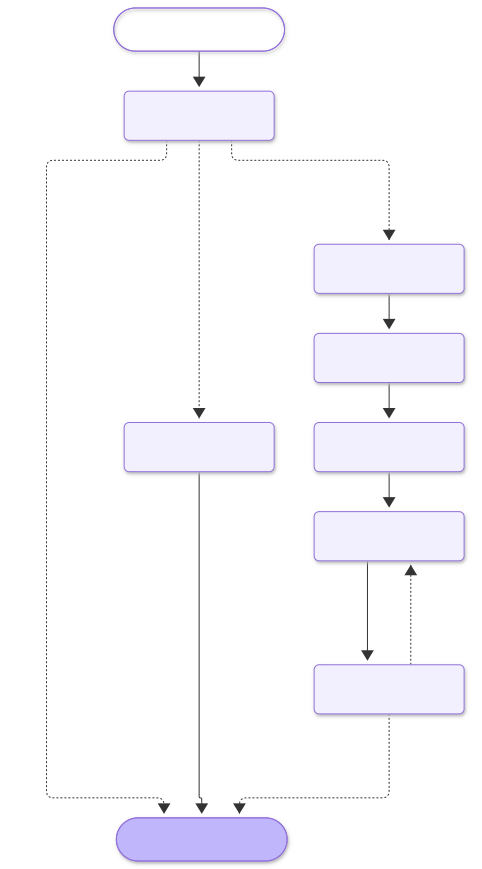

### 图 2：V1.5 动态执行轨迹与跨厂商异构调度追踪图

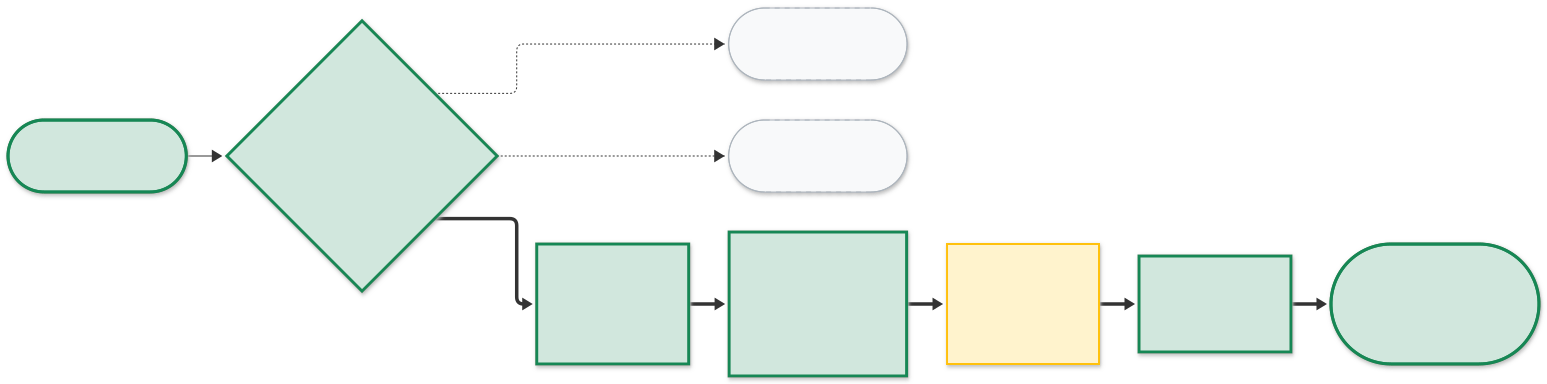

#### 📡 通道健康度统计

| 通道名称                 | 负责角色                       |   成功次数 |   异常切换 | 状态   |
|:-------------------------|:-------------------------------|-----------:|-----------:|:-------|
| ModelScope-Qwen3.5-35B   | debugger,reasoner,coder,judge  |          2 |          1 | 正常   |
| ModelScope-Qwen3.8-27B   | coder,writer,reasoner,debugger |          2 |          1 | 冷却中 |
| Google-Gemini-3.5-Flash  | judge,coder,fast               |          7 |          0 | 正常   |
| Google-Gemini-4-hydrogen | debugger,judge                 |          0 |          0 | 正常   |
| Google-Gemini-3.8-Flash  | coder,judge                    |          0 |          0 | 正常   |
| Zhipu-GLM4-Flash-250414  | fast,writer                    |          0 |          1 | 冷却中 |
| Zhipu-GLM4-Flash         | fast,writer                    |          0 |          1 | 冷却中 |

#### 🔀 异构多模型 FinOps 角色分流统计

| Agent角色   | 模型路由分布                                                                             |
|:------------|:-----------------------------------------------------------------------------------------|
| fast        | Google-Gemini-3.5-Flash: 3次                                                             |
| coder       | ModelScope-Qwen3.5-35B: 1次 | ModelScope-Qwen3.8-27B: 1次 | Google-Gemini-3.5-Flash: 2次 |
| writer      | ModelScope-Qwen3.8-27B: 1次 | Google-Gemini-3.5-Flash: 1次                               |
| reasoner    | ModelScope-Qwen3.5-35B: 1次                                                              |
| judge       | Google-Gemini-3.5-Flash: 1次                                                             |

In [16]:
# ==============================================================================
# V1.5 可观测性中心：完美支持中文的 SVG Mermaid 渲染器 + FinOps 统计
# ==============================================================================
import zlib
import base64
import textwrap
import requests
from IPython.display import SVG, Image, display, Markdown

def render_mermaid_utf8(mermaid_code: str, title: str):
    """
    完美兼容中文的 Mermaid 渲染器：
    优先通过 Kroki / Mermaid.ink (pako UTF-8) 生成矢量 SVG 直接内嵌显示，
    不依赖前端 <script>，不被 Kaggle 安全策略拦截，中文高清不乱码！
    """
    display(Markdown(f"### {title}"))
    clean_code = textwrap.dedent(mermaid_code).strip()
    
    # 通道 1：Kroki POST 接口（原生支持 UTF-8 中文，返回高清 SVG）
    try:
        r = requests.post(
            "https://kroki.io/mermaid/svg",
            data=clean_code.encode("utf-8"),
            headers={"Content-Type": "text/plain; charset=utf-8"},
            timeout=15
        )
        if r.status_code == 200 and "<svg" in r.text:
            display(SVG(r.content))
            return
    except Exception as e1:
        print(f"  [渲染通道1 Kroki 跳过: {e1}]")

    # 通道 2：Mermaid.ink 官方 pako UTF-8 压缩 SVG 接口
    try:
        state_json = json.dumps({"code": clean_code, "mermaid": {"theme": "default"}}, ensure_ascii=False).encode("utf-8")
        pako_b64 = base64.urlsafe_b64encode(zlib.compress(state_json, level=9)).decode("ascii")
        r2 = requests.get(f"https://mermaid.ink/svg/pako:{pako_b64}", timeout=15)
        if r2.status_code == 200 and "<svg" in r2.text:
            display(SVG(r2.content))
            return
    except Exception as e2:
        print(f"  [渲染通道2 Mermaid.ink 跳过: {e2}]")

    print("⚠️ 两个在线 SVG 渲染接口均暂时不可达，已输出标准 Mermaid 源码（可直接粘入 GitHub README 渲染）：")
    print(clean_code)

# 1. 渲染 V1.5 LangGraph 原生状态机拓扑图
render_mermaid_utf8(attribution_app_v15.get_graph().draw_mermaid(), "图 1：V1.5 LangGraph 原生条件状态机拓扑图")

# 2. 渲染测试 3（深度归因）的动态执行轨迹高亮图（采用标准 Mermaid 虚线箭头语法）
lmdi_m = out_slow.get("lmdi_metrics", {})
aud = out_slow.get("audit_result", {})

trace_code = f"""
flowchart LR
    classDef active fill:#D1E7DD,stroke:#198754,stroke-width:3px,color:#0F5132,font-weight:bold;
    classDef inactive fill:#F8F9FA,stroke:#ADB5BD,stroke-width:1px,stroke-dasharray: 5 5,color:#6C757D;
    classDef badge fill:#FFF3CD,stroke:#FFC107,stroke-width:2px,color:#664D03,font-weight:bold;

    Q(["输入: 2018-07 vs 08 异动归因"]):::active --> G{{"Gateway · Zhipu-Flash<br/>命中: SLOW_ATTRIBUTION"}}:::active
    G -.->|未触发| C(["CLARIFY 模糊反问"]):::inactive
    G -.->|未触发| F(["FAST_SQL 极速直查"]):::inactive
    G ==> P["1. Planner · Qwen35B<br/>拆解 {len(out_slow.get('analysis_plan', []))} 个纯中文子任务"]:::active
    P ==> S["2. SQL Agent · Qwen27B+Debugger<br/>重试: {out_slow.get('total_sql_retries', 0)}次 · Debugger介入: {out_slow.get('debugger_triggered', False)}"]:::active
    S ==> M["3. LMDI 确定性沙盒 · 残差={lmdi_m.get('residual', 0)}<br/>单量: {lmdi_m.get('effect_orders', 0):+.0f} · 客单价: {lmdi_m.get('effect_aov', 0):+.0f}"]:::badge
    M ==> R["4. Reporter · Qwen27B<br/>生成次数: {out_slow.get('report_retries', 1)}次"]:::active
    R ==> J(["5. Hybrid Judge · 正则+Gemini<br/>溯源率: {aud.get('regex_grounding_pct', 100)}% · 忠实度: {aud.get('faithfulness_score', 5)}/5"]):::active
"""

render_mermaid_utf8(trace_code, "图 2：V1.5 动态执行轨迹与跨厂商异构调度追踪图")

# 3. 输出异构模型 FinOps 角色分流统计看板
llm.print_stats()

# 6.使用测评集进行对比

In [17]:
# ==============================================================================
# 1. 定义 15 道分层评测集，简单-中等-困难
# ==============================================================================
stratified_benchmark = [
    # ---------------- 简单 (基础取数与单一业务口径对齐) ----------------
    {
        "id": "E1", "difficulty": "Easy", "trap_type": "有效GMV口径(剔除未送达与运费)",
        "question": "统计 2018年8月（2018-08）的总有效GMV（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(SUM(oi.price), 2) AS val
            FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
            WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08';
        """
    },
    {
        "id": "E2", "difficulty": "Easy", "trap_type": "独立买家UV口径(customer_unique_id)",
        "question": "统计 2018年8月（2018-08）产生有效订单的独立买家人数（UV）。",
        "golden_sql": """
            SELECT COUNT(DISTINCT c.customer_unique_id) AS val
            FROM orders o JOIN customers c ON o.customer_id = c.customer_id
            WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08';
        """
    },
    {
        "id": "E3", "difficulty": "Easy", "trap_type": "订单取消率口径(全量分母)",
        "question": "计算 2018年8月（2018-08）下单的订单取消率百分比（保留2位小数，如 0.85 表示 0.85%）。",
        "golden_sql": """
            SELECT ROUND(SUM(CASE WHEN order_status = 'canceled' THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(DISTINCT order_id), 2) AS val
            FROM orders WHERE strftime('%Y-%m', order_purchase_timestamp) = '2018-08';
        """
    },
    {
        "id": "E4", "difficulty": "Easy", "trap_type": "有效件单价ASP口径",
        "question": "计算 2018年7月（2018-07）有效订单的商品件单价 ASP（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(SUM(oi.price) / COUNT(oi.order_item_id), 2) AS val
            FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
            WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-07';
        """
    },
    {
        "id": "E5", "difficulty": "Easy", "trap_type": "平均履约时长(julianday语法)",
        "question": "计算 2018年7月（2018-07）有效订单的平均履约时长（单位：天，保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(AVG(julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp)), 2) AS val
            FROM orders
            WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
              AND strftime('%Y-%m', order_purchase_timestamp) = '2018-07';
        """
    },

    # ---------------- 中等 (多表关联、复合比率与分母防错) ----------------
    {
        "id": "M1", "difficulty": "Medium", "trap_type": "客单价AOV分母防膨胀(去重订单数)",
        "question": "计算 2018年7月（2018-07）的有效客单价 AOV（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(SUM(oi.price) / COUNT(DISTINCT o.order_id), 2) AS val
            FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
            WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-07';
        """
    },
    {
        "id": "M2", "difficulty": "Medium", "trap_type": "订单连带率UPT口径",
        "question": "计算 2018年上半年（2018-01 至 2018-06）有效订单的订单连带率 UPT（保留4位小数）。",
        "golden_sql": """
            SELECT ROUND(COUNT(oi.order_item_id) * 1.0 / COUNT(DISTINCT o.order_id), 4) AS val
            FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
            WHERE o.order_status = 'delivered'
              AND strftime('%Y-%m', o.order_purchase_timestamp) BETWEEN '2018-01' AND '2018-06';
        """
    },
    {
        "id": "M3", "difficulty": "Medium", "trap_type": "四表关联与英文品类Top1有效GMV",
        "question": "查询 2018年8月（2018-08）有效GMV排名第1的英文商品品类，返回该品类的有效GMV金额（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(SUM(oi.price), 2) AS val
            FROM orders o
            JOIN order_items oi ON o.order_id = oi.order_id
            LEFT JOIN products p ON oi.product_id = p.product_id
            LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
            WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
            GROUP BY t.product_category_name_english
            ORDER BY val DESC LIMIT 1;
        """
    },
    {
        "id": "M4", "difficulty": "Medium", "trap_type": "履约延迟率口径",
        "question": "计算 2018年5月（2018-05）有效订单的履约延迟率百分比（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(AVG(CASE WHEN julianday(order_delivered_customer_date) > julianday(order_estimated_delivery_date) THEN 1.0 ELSE 0.0 END) * 100.0, 2) AS val
            FROM orders
            WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
              AND strftime('%Y-%m', order_purchase_timestamp) = '2018-05';
        """
    },
    {
        "id": "M5", "difficulty": "Medium", "trap_type": "参评有效订单差评率(订单级去重)",
        "question": "计算 2018年5月（2018-05）来自圣保罗州（customer_state = 'SP'）的有效订单差评率百分比（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(COUNT(DISTINCT CASE WHEN r.review_score <= 2 THEN o.order_id END) * 100.0 / COUNT(DISTINCT o.order_id), 2) AS val
            FROM orders o
            JOIN customers c ON o.customer_id = c.customer_id
            JOIN order_reviews r ON o.order_id = r.order_id
            WHERE o.order_status = 'delivered' AND c.customer_state = 'SP'
              AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-05';
        """
    },

    # ---------------- 困难 (防扇出膨胀、CTE复购、新老客历史归因、窗口占比) ----------------
    {
        "id": "H1", "difficulty": "Hard", "trap_type": "一对多关联防扇出膨胀(Fan-out Trap)",
        "question": "统计 2018年8月（2018-08）使用信用卡（payment_type = 'credit_card'）支付过的有效订单，其对应的商品有效GMV总和是多少（保留2位小数）？",
        "golden_sql": """
            SELECT ROUND(SUM(oi.price), 2) AS val
            FROM orders o
            JOIN order_items oi ON o.order_id = oi.order_id
            WHERE o.order_status = 'delivered'
              AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
              AND o.order_id IN (SELECT DISTINCT order_id FROM order_payments WHERE payment_type = 'credit_card');
        """
    },
    {
        "id": "H2", "difficulty": "Hard", "trap_type": "CTE二次聚合计算周期用户复购率",
        "question": "计算 2018年全年（2018-01 至 2018-12）产生过有效订单的独立买家中，复购用户（2018年有效订单数 >= 2）的占比百分比（复购率，保留2位小数）。",
        "golden_sql": """
            WITH user_cnt AS (
                SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS cnt
                FROM orders o JOIN customers c ON o.customer_id = c.customer_id
                WHERE o.order_status = 'delivered' AND strftime('%Y', o.order_purchase_timestamp) = '2018'
                GROUP BY c.customer_unique_id
            )
            SELECT ROUND(SUM(CASE WHEN cnt >= 2 THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(customer_unique_id), 2) AS val
            FROM user_cnt;
        """
    },
    {
        "id": "H3", "difficulty": "Hard", "trap_type": "全量历史首单界定老客GMV贡献",
        "question": "在 2018年8月（2018-08）产生有效订单的买家中，历史老客（即在 2018-08-01 之前就有过至少一笔有效订单的独立买家）在 2018年8月 贡献的有效GMV是多少（保留2位小数）？",
        "golden_sql": """
            WITH first_ord AS (
                SELECT c.customer_unique_id, MIN(o.order_purchase_timestamp) AS min_dt
                FROM orders o JOIN customers c ON o.customer_id = c.customer_id
                WHERE o.order_status = 'delivered'
                GROUP BY c.customer_unique_id
            )
            SELECT ROUND(SUM(oi.price), 2) AS val
            FROM orders o
            JOIN order_items oi ON o.order_id = oi.order_id
            JOIN customers c ON o.customer_id = c.customer_id
            JOIN first_ord fo ON c.customer_unique_id = fo.customer_unique_id
            WHERE o.order_status = 'delivered'
              AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
              AND fo.min_dt < '2018-08-01';
        """
    },
    {
        "id": "H4", "difficulty": "Hard", "trap_type": "帕累托头部Top3品类集中度占比",
        "question": "在 2018年8月（2018-08）中，有效GMV排名前 3 的英文商品品类，其合计有效GMV占当月大盘总有效GMV的百分比是多少（保留2位小数）？",
        "golden_sql": """
            WITH cat_gmv AS (
                SELECT COALESCE(t.product_category_name_english, 'unknown') AS cat, SUM(oi.price) AS gmv
                FROM orders o
                JOIN order_items oi ON o.order_id = oi.order_id
                LEFT JOIN products p ON oi.product_id = p.product_id
                LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
                WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
                GROUP BY 1 ORDER BY gmv DESC
            )
            SELECT ROUND((SELECT SUM(gmv) FROM (SELECT gmv FROM cat_gmv LIMIT 3)) * 100.0 / SUM(gmv), 2) AS val
            FROM cat_gmv;
        """
    },
    {
        "id": "H5", "difficulty": "Hard", "trap_type": "跨月CTE透视与门槛过滤求最高环比增速",
        "question": "对比 2018年7月（2018-07）与 2018年8月（2018-08），在两个月有效GMV均超过 30000 的英文商品品类中，8月相比7月有效GMV环比增长率最高的品类，其环比增长率百分比是多少（保留2位小数）？",
        "golden_sql": """
            WITH m_cat AS (
                SELECT COALESCE(t.product_category_name_english, 'unknown') AS cat,
                       SUM(CASE WHEN strftime('%Y-%m', o.order_purchase_timestamp) = '2018-07' THEN oi.price ELSE 0 END) AS gmv_07,
                       SUM(CASE WHEN strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08' THEN oi.price ELSE 0 END) AS gmv_08
                FROM orders o
                JOIN order_items oi ON o.order_id = oi.order_id
                LEFT JOIN products p ON oi.product_id = p.product_id
                LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
                WHERE o.order_status = 'delivered'
                  AND strftime('%Y-%m', o.order_purchase_timestamp) IN ('2018-07', '2018-08')
                GROUP BY 1
                HAVING gmv_07 > 30000 AND gmv_08 > 30000
            )
            SELECT ROUND((gmv_08 - gmv_07) * 100.0 / gmv_07, 2) AS val
            FROM m_cat ORDER BY val DESC LIMIT 1;
        """
    }
]

# ==============================================================================
# 2. 定义 Baseline 模型（仅提供原始基础表字段名，无业务口径字典 RAG，无自纠错）
# ==============================================================================
def run_naive_baseline(question: str) -> str:
    prompt = f"""
            你是一名资深BI数据分析师，请编写 SQLite 查询语句回答问题：{question}，数据库包含以下表及字段：
            - orders(order_id, customer_id, order_status, order_purchase_timestamp, order_delivered_customer_date, order_estimated_delivery_date)
            - order_items(order_id, order_item_id, product_id, price, freight_value)
            - order_payments(order_id, payment_sequential, payment_type, payment_value)
            - customers(customer_id, customer_unique_id, customer_state)
            - products(product_id, product_category_name)
            - category_translation(product_category_name, product_category_name_english)
            - order_reviews(review_id, order_id, review_score)
            要求：只返回最终要求的单个数值列，只输出 ```sql 代码块。
    """
    resp = llm_sql_gen.invoke([HumanMessage(content=prompt)]).content
    return resp.split("```sql")[-1].split("```")[0].strip() if "```sql" in resp else resp.strip()

def extract_and_match(df: pd.DataFrame, gt_val: float, tol: float = 0.05) -> tuple:
    """智能提取 DataFrame 第一行中的数值并与标准答案比对"""
    if df is None or df.empty:
        return "Empty/Err", False
    numeric_vals = []
    for col in df.columns:
        try:
            v = float(df.iloc[0][col])
            numeric_vals.append(round(v, 2))
            if abs(v - float(gt_val)) <= tol:
                return round(v, 2), True
        except:
            continue
    return (numeric_vals[-1] if numeric_vals else "Non-Num"), False

# ==============================================================================
# 3. 批量执行 15 道分层评测并汇总指标
# ==============================================================================
print("开始运行 15 道分层评测集...\n")
eval_results = []
for item in stratified_benchmark:
    # 1. 计算 Ground Truth 标准答案
    gt_df = pd.read_sql(item["golden_sql"], conn)
    gt_val = round(float(gt_df.iloc[0, 0]), 2)
    
    # 2. 评测 Baseline (无业务口径 RAG)
    try:
        base_sql = run_naive_baseline(item["question"])
        base_df = pd.read_sql(base_sql, conn)
        base_val, base_ok = extract_and_match(base_df, gt_val)
    except Exception as e:
        base_val, base_ok = "SQL_Error", False
        
    # 3. 评测 我们的 BI Agent (口径 RAG + 自纠错闭环)

    agent_out = execute_sql_with_self_correction(
        item["question"] + "（注意：SELECT 子句请只返回最终要求的这 1 个数值列 AS val）",
        max_retries=3, verbose=False
    )
    agent_val, agent_ok = extract_and_match(agent_out["df"], gt_val)
    
    print(f'''[{item['id']} | 
            {item['difficulty']:<6}] {item['trap_type']:<28} | 
            GT: {gt_val:<10} | 
            Base: {str(base_val):<10} ({'✅' if base_ok else '❌'}) | 
            Agent: {str(agent_val):<10} ({'✅' if agent_ok else '❌'} 
            重试:{agent_out['attempts']}次)'''
         )
    
    eval_results.append({
        "题号": item["id"],
        "难度": item["difficulty"],
        "考察业务痛点/陷阱": item["trap_type"],
        "标准答案(GT)": gt_val,
        "Baseline输出": base_val,
        "Baseline正确": 1 if base_ok else 0,
        "Agent输出": agent_val,
        "Agent正确": 1 if agent_ok else 0,
        "Agent尝试次数": agent_out["attempts"]
    })

df_detail = pd.DataFrame(eval_results)

# 4. 计算分难度准确率汇总看板 (Summary Table)
summary_df = df_detail.groupby("难度", sort=False).agg(
    题目数=("题号", "count"),
    Baseline准确率=("Baseline正确", lambda x: f"{x.mean()*100:.1f}%"),
    Agent准确率=("Agent正确", lambda x: f"{x.mean()*100:.1f}%"),
    平均执行次数=("Agent尝试次数", "mean")
).reset_index()

total_row = pd.DataFrame([{
    "难度": "Overall (总计)",
    "题目数": len(df_detail),
    "Baseline准确率": f"{df_detail['Baseline正确'].mean()*100:.1f}%",
    "Agent准确率": f"{df_detail['Agent正确'].mean()*100:.1f}%",
    "平均执行次数": round(df_detail["Agent尝试次数"].mean(), 2)
}])
summary_df = pd.concat([summary_df, total_row], ignore_index=True)

display(Markdown("--- \n ### 分层评测汇总看板"))
display(Markdown(summary_df.to_markdown(index=False)))

display(Markdown("### 15道评测题逐题对比明细表"))
display(Markdown(df_detail.to_markdown(index=False)))

开始运行 15 道分层评测集...

  ⚠️ 通道 [ModelScope-Qwen3.5-35B] 请求超时(熔断120s) -> 秒切下一通道
[E1 | 
            Easy  ] 有效GMV口径(剔除未送达与运费)            | 
            GT: 838576.64  | 
            Base: 996973.51  (❌) | 
            Agent: 838576.64  (✅ 
            重试:1次)
  ⚠️ 通道 [ModelScope-Qwen3.8-27B] 请求超时(熔断120s) -> 秒切下一通道
[E2 | 
            Easy  ] 独立买家UV口径(customer_unique_id) | 
            GT: 6310.0     | 
            Base: 6380.0     (❌) | 
            Agent: 6310.0     (✅ 
            重试:1次)
[E3 | 
            Easy  ] 订单取消率口径(全量分母)                | 
            GT: 1.29       | 
            Base: 1.29       (✅) | 
            Agent: 1.29       (✅ 
            重试:1次)
[E4 | 
            Easy  ] 有效件单价ASP口径                   | 
            GT: 124.65     | 
            Base: 105.7      (❌) | 
            Agent: 124.65     (✅ 
            重试:1次)
[E5 | 
            Easy  ] 平均履约时长(julianday语法)          | 
            GT: 8.96       | 
            Base: 8.96       (✅) | 
            Agent: 8.96       (✅

--- 
 ### 分层评测汇总看板

| 难度           |   题目数 | Baseline准确率   | Agent准确率   |   平均执行次数 |
|:---------------|---------:|:-----------------|:--------------|---------------:|
| Easy           |        5 | 40.0%            | 100.0%        |              1 |
| Medium         |        5 | 60.0%            | 100.0%        |              1 |
| Hard           |        5 | 20.0%            | 100.0%        |              1 |
| Overall (总计) |       15 | 40.0%            | 100.0%        |              1 |

### 15道评测题逐题对比明细表

| 题号   | 难度   | 考察业务痛点/陷阱                   |   标准答案(GT) | Baseline输出   |   Baseline正确 |   Agent输出 |   Agent正确 |   Agent尝试次数 |
|:-------|:-------|:------------------------------------|---------------:|:---------------|---------------:|------------:|------------:|----------------:|
| E1     | Easy   | 有效GMV口径(剔除未送达与运费)       |      838577    | 996973.51      |              0 |   838577    |           1 |               1 |
| E2     | Easy   | 独立买家UV口径(customer_unique_id)  |        6310    | 6380.0         |              0 |     6310    |           1 |               1 |
| E3     | Easy   | 订单取消率口径(全量分母)            |           1.29 | 1.29           |              1 |        1.29 |           1 |               1 |
| E4     | Easy   | 有效件单价ASP口径                   |         124.65 | 105.7          |              0 |      124.65 |           1 |               1 |
| E5     | Easy   | 平均履约时长(julianday语法)         |           8.96 | 8.96           |              1 |        8.96 |           1 |               1 |
| M1     | Medium | 客单价AOV分母防膨胀(去重订单数)     |         140.92 | 166.89         |              0 |      140.92 |           1 |               1 |
| M2     | Medium | 订单连带率UPT口径                   |           1.15 | 1.15           |              1 |        1.15 |           1 |               1 |
| M3     | Medium | 四表关联与英文品类Top1有效GMV       |      119391    | 136823.27      |              0 |   119391    |           1 |               1 |
| M4     | Medium | 履约延迟率口径                      |           8.24 | 8.24           |              1 |        8.24 |           1 |               1 |
| M5     | Medium | 参评有效订单差评率(订单级去重)      |           9.02 | 9.03           |              1 |        9.05 |           1 |               1 |
| H1     | Hard   | 一对多关联防扇出膨胀(Fan-out Trap)  |      677561    | 806491.27      |              0 |   677561    |           1 |               1 |
| H2     | Hard   | CTE二次聚合计算周期用户复购率       |           2.1  | 2.12           |              1 |        2.1  |           1 |               1 |
| H3     | Hard   | 全量历史首单界定老客GMV贡献         |       18517.6  | 23052.28       |              0 |    18517.6  |           1 |               1 |
| H4     | Hard   | 帕累托头部Top3品类集中度占比        |          29.82 | 29.38          |              0 |       29.82 |           1 |               1 |
| H5     | Hard   | 跨月CTE透视与门槛过滤求最高环比增速 |          15.33 | SQL_Error      |              0 |       15.33 |           1 |               1 |